In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [4]:
def getRcAndErr(df, ob):
    if (ob == 'bs'):
        nos = df[df.bs==-1].shape[0]
        nss = df[df.bs==+1].shape[0]
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n = nss+nos
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err

In [5]:
def getMcRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['w'])
        nss = sum(df[df.bs==+1]['w'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n_array = []
    wtot_array = []
    for i in range(0, len(w_array)):
        n_array.append( df[df.w == w_array[i]].shape[0] )
        wtot_array.append( sum(df[df.w == w_array[i]]['w']) )
    n = 0
    for i in range(0, len(w_array)):
        if (wtot_array[i] != 0):
            n += wtot_array[i]*n_array[i]/sum(wtot_array)
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err

In [6]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [7]:
observables1 = ['pt','m','q2','rg','zg','mg','b']
file = uproot.open('/vast/palmer/home.grace/ys668/output/run12/data0613_chargedrc.root')
tree = file["ResultTree"].arrays(observables1, library='np')
df = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b'])))), columns=["pts","bs"])
df = applyCut(df, 'pts>15 and bs!=-9 and bs!=0')

In [8]:
df.shape[0]

659347

In [11]:
observables1 = ['pt','b','dr','z','epair','w','reject','pt1','pt2','qlead','qsublead','y1','y2','phi1','phi2']
observabless1 = ['pts','bs','drs','zs','epairs','ws','rejects','pt1s','pt2s','qleads','qsubleads','y1s','y2s','phi1s','phi2s']
df_pythia= applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0615_chargedrc.root', "MatchedTree"),'pts>15 and bs!=-9 and bs!=0 and reject<=0 and rejects<=0')

In [20]:
df_pythia = applyCut(df_pythia, 'not (pts>25 and w>4e-9)') # removes one high weight jet

In [21]:
w_array = np.unique(df_pythia['w'])

In [22]:
df_pythia_pts_array = [ df_pythia[(df_pythia.pts>20) & (df_pythia.pts<25)],\
                       df_pythia[(df_pythia.pts>25) & (df_pythia.pts<30)],\
                       df_pythia[(df_pythia.pts>30) & (df_pythia.pts<40)] ]

In [23]:
rc_pythia_bs_vs_pts_array = []
rc_err_pythia_bs_vs_pts_array = []
for i in range(0, len(df_pythia_pts_array)):
    rc_pythia_bs_vs_pts_array.append(getMcRcAndErr(df_pythia_pts_array[i], 'bs')[0])
    rc_err_pythia_bs_vs_pts_array.append(getMcRcAndErr(df_pythia_pts_array[i], 'bs')[1])

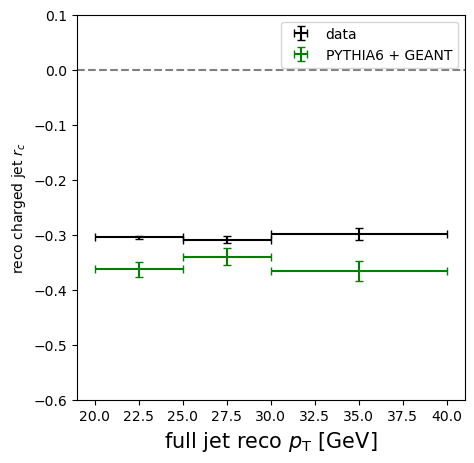

In [24]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], [data_rc_20, data_rc_25, data_rc_30], xerr=[2.5, 2.5, 5], yerr=[data_rc_err_20, data_rc_err_25, data_rc_err_30], capsize=3, ls='none', label='data', color='k')
plt.errorbar([22.5, 27.5, 35], rc_pythia_bs_vs_pts_array, xerr=[2.5, 2.5, 5], yerr=rc_err_pythia_bs_vs_pts_array, capsize=3, ls='none', label='PYTHIA6 + GEANT', color='g')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(fontsize=10)

In [9]:
df_20 = applyCut(df, '20 < pts < 25')
df_25 = applyCut(df, '25 < pts < 30')
df_30 = applyCut(df, '30 < pts < 40')

In [7]:
print(getRcAndErr(df_20, 'bs'))
print(getRcAndErr(df_25, 'bs'))
print(getRcAndErr(df_30, 'bs'))

(-0.3049137767841851, 0.002859432635262245)
(-0.30877555891479036, 0.005998971104851678)
(-0.2980493793479744, 0.011148521567582732)


In [1]:
data_rc_20, data_rc_err_20 = getRcAndErr(df_20, 'bs')
data_rc_25, data_rc_err_25 = getRcAndErr(df_25, 'bs')
data_rc_30, data_rc_err_30 = getRcAndErr(df_30, 'bs')

NameError: name 'getRcAndErr' is not defined

In [ ]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [28]:
y_rec_20,yerr_rec_20,x = calc_hist(df_20[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins))
y_rec_25,yerr_rec_25,x = calc_hist(df_25[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins))
y_rec_30,yerr_rec_30,x = calc_hist(df_30[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins))

In [29]:
data_array = np.array([y_rec_20/sum(y_rec_20),y_rec_25/sum(y_rec_25),y_rec_30/sum(y_rec_30)])

In [30]:
data_err_array = np.array([yerr_rec_20/sum(y_rec_20),yerr_rec_25/sum(y_rec_25),yerr_rec_30/sum(y_rec_30)])

In [31]:
print(data_array)
print(data_err_array)

[[0.65245689 0.34754311]
 [0.65438778 0.34561222]
 [0.64902469 0.35097531]]
[[0.00242519 0.00177   ]
 [0.00510214 0.00370791]
 [0.00940912 0.00691921]]


In [32]:
fake_rate_array = np.array([0.27973313, 0.23650474, 0.22628239])

In [33]:
fake_dist_array = np.array([[0.60864417, 0.39135583], [0.59417459,0.40582541], [0.60064745, 0.39935255]])

In [34]:
fake_err_array = np.array([[0.02912147, 0.02331168], [0.02493272, 0.02715528], [0.05058158, 0.04618194]])

In [35]:
def getMatched_sub(data, fake_rate, fake_dist):
    return (data - fake_rate * fake_dist)/(1 - fake_rate)

In [36]:
y1_array = []
rc1_array = []
for i in range(0,3):
    print(i)
    print(data_array[i])
    #print(getRc(data_array[i]))
    y1 = getMatched_sub(data_array[i], fake_rate_array[i], fake_dist_array[i])
    y1_array.append(y1)
    print(y1)
    rc1_array.append((y1[1]-y1[0]) / (y1[1]+y1[0]))
    #print(getRc(y1))

0
[0.65245689 0.34754311]
[0.66947262 0.33052738]
1
[0.65438778 0.34561222]
[0.67303977 0.32696023]
2
[0.64902469 0.35097531]
[0.66317316 0.33682684]


In [37]:
def getMatched_err_sub(data_err, fake_rate, fake_err):
    return (np.sqrt(data_err**2 + (fake_rate * fake_err)**2))/(1 - fake_rate)

In [38]:
yerr1_array = []
rc1_err_array = []
for i in range(0,3):
    #print(i)
    #print(data_array[i])
    #print(getRc(data_array[i]))
    yerr1 = getMatched_err_sub(data_err_array[i], fake_rate_array[i], fake_err_array[i])
    yerr1_array.append(yerr1)
    rc1_err_array.append(yerr1[1]*2)
    #print(getRc(y1))

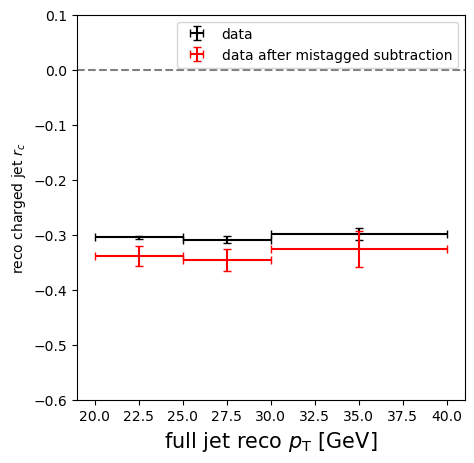

In [39]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], [data_rc_20, data_rc_25, data_rc_30], xerr=[2.5, 2.5, 5], yerr=[data_rc_err_20, data_rc_err_25, data_rc_err_30], capsize=3, ls='none', label='data', color='k')
plt.errorbar([22.5, 27.5, 35], rc1_array, xerr=[2.5, 2.5, 5], yerr=rc1_err_array, capsize=3, ls='none', label='data after mistagged subtraction', color='r')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(fontsize=10)

In [40]:
rc1_array

[-0.3389452430645336, -0.34607953567344624, -0.3263463116487207]

In [41]:
rc1_err_array

[0.01876247854512618, 0.01942612024012323, 0.03239737441659678]